In [56]:
#Importing important Python Libraries 
import pandas as pd
import numpy as np
from datetime import date
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

In [4]:
#Loading Dataset
data_df = pd.read_csv("Stock Trading of Nepal Infrastructure Bank Limited.csv")
data_df = data_df.drop(columns=["Symbol", "Percent Change"])
data_df["Date"] = pd.to_datetime(data_df["Date"], dayfirst= True)
data_df["Volume"] = pd.to_numeric(data_df["Volume"].str.replace(",",""), errors = "coerce").astype(int)
data_df["Turn Over"] = pd.to_numeric(data_df["Turn Over"].str.replace(",",""), errors = "coerce").astype(float)
data_df.head()

,Date,Open,High,Low,Close,Volume,Turn Over
0,2026-10-16,249.0,250.0,246.5,246.5,64196,15954492.7
1,2026-10-15,245.1,249.5,245.1,249.0,83609,20728077.7
2,2026-10-14,243.0,247.3,242.0,247.0,52929,12971672.1
3,2026-10-13,243.0,246.9,242.4,244.3,42035,10281930.1
4,2026-10-12,245.0,250.0,244.0,244.1,71272,17550463.8


Inserting Additional Features

In [ ]:
#Inserting Average Price and Return (Rate of Return) for the Day
data_df["Avg_Price"] = data_df["Turn Over"] / data_df["Volume"]
data_df["Return"] = (data_df.Close[::-1].pct_change() * 100).round(3)

In [7]:
#Return based on Previous Close Price and related Features
prev_close = data_df["Close"].shift(-1)
data_df["Ret_1d"] = (((data_df["Close"]-prev_close)/prev_close) * 100).round(3) #today vs yesterday
data_df["Ret_lag1d"] = data_df["Ret_1d"].shift(-1) #yesterday's Return
data_df["Ret_lag1d"] = data_df["Ret_1d"].shift(-2) #return 2 days ago
data_df["Ret_5d"] = (((data_df["Close"]-data_df["Close"].shift(-5))/data_df["Close"].shift(-5)) * 100).round(3) #today vs last 5 days

In [ ]:
#Calculating the range of movement for the day i.e. the difference between high price and low price for Candle Shape of today
data_df["Gap"] = (((data_df["Open"] - prev_close)/prev_close)*100).round(3)
data_df["Range"] = (((data_df["High"] - data_df["Low"])/ data_df["Close"])*100).round(3)
daily_range= (data_df["High"] - data_df["Low"]).replace(0, np.nan)
data_df["Close_Position"] = (((data_df["Close"]-data_df["Low"]) / daily_range) * 100).fillna(0.5) #0 = closed at low, 1 = close at high

In [9]:
#Calculating Moving Averages and Comparision with close price
for n in (5, 20):
    Moving_Avg = data_df["Close"][::-1].rolling(n).mean()[::-1]
    data_df[f"Close_vs_MA{n}"] = ((data_df["Close"]- Moving_Avg) / Moving_Avg) * 100

In [10]:
#Calculating volatility of stock and volume ratio for the last 10 days
data_df["Volatility10"]= data_df.Return[::-1].rolling(10).std().round(3)
data_df["Vol_ratio10"] = data_df.Volume[::-1]/data_df.Volume[::-1].rolling(10).mean()
data_df["Log_Volume"] = np.log1p(data_df["Volume"])  #Normalizing data that is heavily right skewed

In [11]:
#Creating prediction target
data_df["Next_Close"] = data_df["Close"].shift(1)
data_df["Target"] = (data_df["Next_Close"] > data_df["Close"]).astype(int)

Understanding Dataset after Feature Modification

In [12]:
data_df.head()

,Date,Open,High,Low,Close,Volume,Turn Over,Avg_Price,Return,Ret_1d,...,Gap,Range,Close_Position,Close_vs_MA5,Close_vs_MA20,Volatility10,Vol_ratio10,Log_Volume,Next_Close,Target
0,2026-10-16,249.0,250.0,246.5,246.5,64196,15954492.7,248.527832,-1.004,-1.004,...,0.000,1.420,0.000000,0.129986,-0.576776,0.869,1.138134,11.069712,NaN,0
1,2026-10-15,245.1,249.5,245.1,249.0,83609,20728077.7,247.916824,0.810,0.810,...,-0.769,1.767,88.636364,1.227742,0.344557,0.810,1.501625,11.333918,246.5,0
2,2026-10-14,243.0,247.3,242.0,247.0,52929,12971672.1,245.076841,1.105,1.105,...,-0.532,2.146,94.339623,0.750530,-0.581618,0.797,0.993739,10.876726,249.0,1
3,2026-10-13,243.0,246.9,242.4,244.3,42035,10281930.1,244.604023,0.082,0.082,...,-0.451,1.842,42.222222,0.057339,-1.666398,0.912,0.785214,10.646282,247.0,1
4,2026-10-12,245.0,250.0,244.0,244.1,71272,17550463.8,246.246265,-0.570,-0.570,...,-0.204,2.458,1.666667,0.073795,-1.740968,0.910,1.169408,11.174273,244.3,1


In [13]:
data_df.shape

(1167, 22)

In [14]:
data_df.isna().sum()

Date               0
Open               0
High               0
Low                0
Close              0
Volume             0
Turn Over          0
Avg_Price          0
Return             1
Ret_1d             1
Ret_lag1d          3
Ret_5d             5
Gap                1
Range              0
Close_Position     0
Close_vs_MA5       4
Close_vs_MA20     19
Volatility10      10
Vol_ratio10        9
Log_Volume         0
Next_Close         1
Target             0
dtype: int64

Handling Missing Values

Missing values are created only after feature engineering and are found in the earliest datas. 

There is maximum missing value in close vs 20 days moving average because the first few days don't have enough history to fill the window. For consistency and accuracy, it is better to drop these missing values. 

However, there is a missing value on the initial entry of next close column. Dropping this would be counter productive to predict tomorrow's price movement.

In [15]:
print("Rows before dropna:", len(data_df))          
tmp = data_df.replace([np.inf, -np.inf], np.nan)

bad = tmp.isna().any(axis=1)
print("Rows that will be dropped:", bad.sum())

Rows before dropna: 1167
Rows that will be dropped: 20


In [16]:
latest_row = data_df.iloc[0].copy() #Creating a copy of latest data so it doesn't get lost
data_df = data_df[1:] #Removing latest row so that dropna does not delete it
data_df = data_df.replace([np.inf, -np.inf], np.nan).dropna(axis=0)

In [17]:
data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1147 entries, 1 to 1147
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            1147 non-null   datetime64[us]
 1   Open            1147 non-null   float64       
 2   High            1147 non-null   float64       
 3   Low             1147 non-null   float64       
 4   Close           1147 non-null   float64       
 5   Volume          1147 non-null   int64         
 6   Turn Over       1147 non-null   float64       
 7   Avg_Price       1147 non-null   float64       
 8   Return          1147 non-null   float64       
 9   Ret_1d          1147 non-null   float64       
 10  Ret_lag1d       1147 non-null   float64       
 11  Ret_5d          1147 non-null   float64       
 12  Gap             1147 non-null   float64       
 13  Range           1147 non-null   float64       
 14  Close_Position  1147 non-null   float64       
 15  Close_vs_MA5   

### Machine Learning Model

In [20]:
#Filtering features for model
drop_cols = ["Date", "Open", "High", "Low", "Close", "Volume", "Turn Over", "Next_Close", "Target"]
feature_columns = [c for c in data_df.columns if c not in drop_cols]

In [ ]:
X = data_df[feature_columns].to_numpy()
y = data_df["Target"].to_numpy()

In [32]:
#Chronological Train/ Test Split on newest data
test_size =  int(len(data_df) * 0.2)
X_train, y_train = X[test_size:], y[test_size:]
X_test, y_test = X[:test_size], y[:test_size]

print ("Train set: ", data_df["Date"].iloc[-1].date(), "to", data_df["Date"].iloc[test_size].date())
print ("Test set : ", data_df["Date"].iloc[test_size -1].date(), "to", data_df["Date"].iloc[0].date())

Train set:  2021-11-09 to 2025-10-28
Test set :  2025-10-29 to 2026-10-15


In [37]:
pipe = make_pipeline(StandardScaler(), LogisticRegression())
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [39]:
pipe.score(X_test, y_test)

0.5938864628820961

In [45]:
baseline = max(y_test.mean(), 1- y_test.mean())
print ("Baseline Accuracy =", baseline.round(2))

Baseline Accuracy = 0.58


In [59]:
y_pred = pipe.predict(X_test)
y_prob = pipe.predict_proba(X_test)

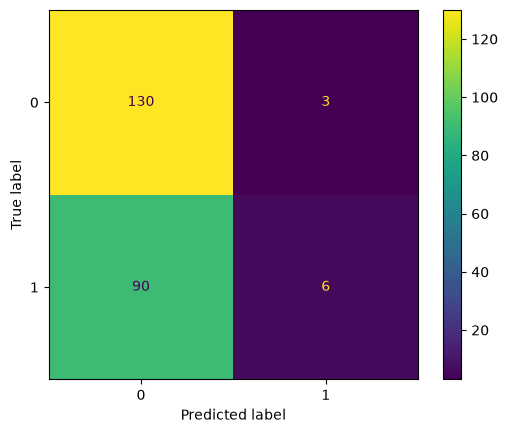

In [ ]:
#Confusion matrix
matrix = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(matrix).plot()

In [ ]:
#Classification Report (Accuracy, Precision, Recall and F1-Score) and ROC-AOC 
print(classification_report(y_test, y_pred))
print("ROC-AOU = ", ((roc_auc_score(y_test, y_prob[:,0])) * 100), "%")

              precision    recall  f1-score   support

           0       0.59      0.98      0.74       133
           1       0.67      0.06      0.11        96

    accuracy                           0.59       229
   macro avg       0.63      0.52      0.43       229
weighted avg       0.62      0.59      0.48       229

ROC-AOU =  47.04730576441103 %


In [72]:
#Predict the next day trading movement
